In [1]:
# ============================================
# CELL 1 — Imports
# ============================================
import numpy as np
import xarray as xr
import matplotlib.pyplot as plt
import subprocess
import os
import glob
from pathlib import Path

print("Imports ready")

Imports ready


In [2]:
# ============================================
# CELL 2 — Set up STILT project
# ============================================
os.makedirs("../stilt_project", exist_ok=True)
os.makedirs("../training_data", exist_ok=True)

# Create STILT project via R
stilt_setup = """
library(devtools)
uataq::stilt_init("../stilt_project")
"""

with open("setup_stilt.R", "w") as f:
    f.write(stilt_setup)

subprocess.run(["Rscript", "setup_stilt.R"])
print("STILT project created")

STILT project created


Error in library(devtools) : there is no package called ‘devtools’
Execution halted


In [3]:
# ============================================
# CELL 3 — Define receptor locations
# These are the points where we "measure" atmosphere
# Start with 10 locations across Permian Basin (Texas)
# Biggest methane hotspot in the US
# ============================================
receptors = [
    {"name": "permian_01", "lat": 31.85, "lon": -102.10},
    {"name": "permian_02", "lat": 31.90, "lon": -102.30},
    {"name": "permian_03", "lat": 32.10, "lon": -102.50},
    {"name": "permian_04", "lat": 31.70, "lon": -102.20},
    {"name": "permian_05", "lat": 32.20, "lon": -101.90},
    {"name": "permian_06", "lat": 31.60, "lon": -102.40},
    {"name": "permian_07", "lat": 32.00, "lon": -102.80},
    {"name": "permian_08", "lat": 31.80, "lon": -101.80},
    {"name": "permian_09", "lat": 32.30, "lon": -102.10},
    {"name": "permian_10", "lat": 31.50, "lon": -102.60},
]

print(f"Defined {len(receptors)} receptor locations")
for r in receptors:
    print(f"  {r['name']}: {r['lat']}N, {r['lon']}W")

Defined 10 receptor locations
  permian_01: 31.85N, -102.1W
  permian_02: 31.9N, -102.3W
  permian_03: 32.1N, -102.5W
  permian_04: 31.7N, -102.2W
  permian_05: 32.2N, -101.9W
  permian_06: 31.6N, -102.4W
  permian_07: 32.0N, -102.8W
  permian_08: 31.8N, -101.8W
  permian_09: 32.3N, -102.1W
  permian_10: 31.5N, -102.6W


In [4]:
# ============================================
# CELL 4 — Generate synthetic training data
# While STILT installs, use this to start training
# This generates realistic footprint patterns
# mathematically — good enough for first model
# ============================================
def generate_synthetic_footprint(wind_u, wind_v, source_lat, source_lon, 
                                  grid_size=64):
    """
    Generate synthetic atmospheric footprint.
    Simulates what STILT would produce.
    For initial training before STILT is ready.
    """
    x = np.linspace(-2, 2, grid_size)
    y = np.linspace(-2, 2, grid_size)
    xx, yy = np.meshgrid(x, y)
    
    # Wind direction determines footprint shape
    wind_speed = np.sqrt(wind_u**2 + wind_v**2) + 0.1
    wind_dir_x = wind_u / wind_speed
    wind_dir_y = wind_v / wind_speed
    
    # Footprint is upwind of receptor
    upwind_x = -wind_dir_x
    upwind_y = -wind_dir_y
    
    # Gaussian footprint centered upwind
    sigma_along = 0.3 + 0.1 * wind_speed
    sigma_cross = 0.15
    
    # Rotate to wind direction
    cos_a = wind_dir_x
    sin_a = wind_dir_y
    xx_rot = xx * cos_a + yy * sin_a
    yy_rot = -xx * sin_a + yy * cos_a
    
    footprint = np.exp(
        -(xx_rot - 0.5)**2 / (2 * sigma_along**2) 
        - yy_rot**2 / (2 * sigma_cross**2)
    )
    
    # Add realistic noise
    footprint += np.random.exponential(0.01, footprint.shape)
    
    # Normalize (mass conservation)
    footprint = np.maximum(footprint, 0)
    footprint /= (footprint.sum() + 1e-8)
    
    return footprint

print("Synthetic footprint generator ready")

Synthetic footprint generator ready


In [5]:
# ============================================
# CELL 5 — Generate 5,000 training pairs
# wind_field → footprint
# This is your training dataset
# ============================================
np.random.seed(42)
N_SAMPLES = 5000
GRID_SIZE = 64

print(f"Generating {N_SAMPLES} training pairs...")

for i in range(N_SAMPLES):
    # Random wind conditions
    wind_u = np.random.uniform(-15, 15, (GRID_SIZE, GRID_SIZE))
    wind_v = np.random.uniform(-15, 15, (GRID_SIZE, GRID_SIZE))
    temp   = np.random.uniform(270, 310, (GRID_SIZE, GRID_SIZE))
    blh    = np.random.uniform(200, 2000, (GRID_SIZE, GRID_SIZE))
    press  = np.random.uniform(850, 1013, (GRID_SIZE, GRID_SIZE))
    stab   = np.random.uniform(0, 1, (GRID_SIZE, GRID_SIZE))
    
    # Stack into 6-channel input tensor [6, 64, 64]
    wind_field = np.stack([wind_u, wind_v, temp, blh, press, stab])
    
    # Generate corresponding footprint [1, 64, 64]
    mean_u = wind_u.mean()
    mean_v = wind_v.mean()
    footprint = generate_synthetic_footprint(mean_u, mean_v, 0, 0, GRID_SIZE)
    footprint = footprint[np.newaxis, :, :]
    
    # Save as compressed numpy file
    np.savez_compressed(
        f"../training_data/sample_{i:06d}.npz",
        wind_field=wind_field.astype(np.float32),
        footprint=footprint.astype(np.float32)
    )
    
    if (i + 1) % 500 == 0:
        print(f"  Generated {i+1}/{N_SAMPLES} samples")

print(f"\nDone — {N_SAMPLES} training pairs saved to training_data/")

Generating 5000 training pairs...
  Generated 500/5000 samples
  Generated 1000/5000 samples
  Generated 1500/5000 samples
  Generated 2000/5000 samples
  Generated 2500/5000 samples
  Generated 3000/5000 samples
  Generated 3500/5000 samples
  Generated 4000/5000 samples
  Generated 4500/5000 samples
  Generated 5000/5000 samples

Done — 5000 training pairs saved to training_data/


In [6]:
# ============================================
# CELL 6 — Verify training data
# ============================================
files = glob.glob("../training_data/*.npz")
print(f"Total files: {len(files)}")

# Load and inspect one sample
sample = np.load(files[0])
wind_field = sample['wind_field']
footprint  = sample['footprint']

print(f"\nSample shapes:")
print(f"  wind_field: {wind_field.shape}")
print(f"  footprint:  {footprint.shape}")
print(f"\nWind field stats:")
print(f"  min: {wind_field.min():.3f}")
print(f"  max: {wind_field.max():.3f}")
print(f"\nFootprint stats:")
print(f"  sum: {footprint.sum():.6f} (should be ~1.0)")
print(f"  max: {footprint.max():.6f}")

Total files: 5000

Sample shapes:
  wind_field: (6, 64, 64)
  footprint:  (1, 64, 64)

Wind field stats:
  min: -14.995
  max: 1999.322

Footprint stats:
  sum: 1.000000 (should be ~1.0)
  max: 0.005681


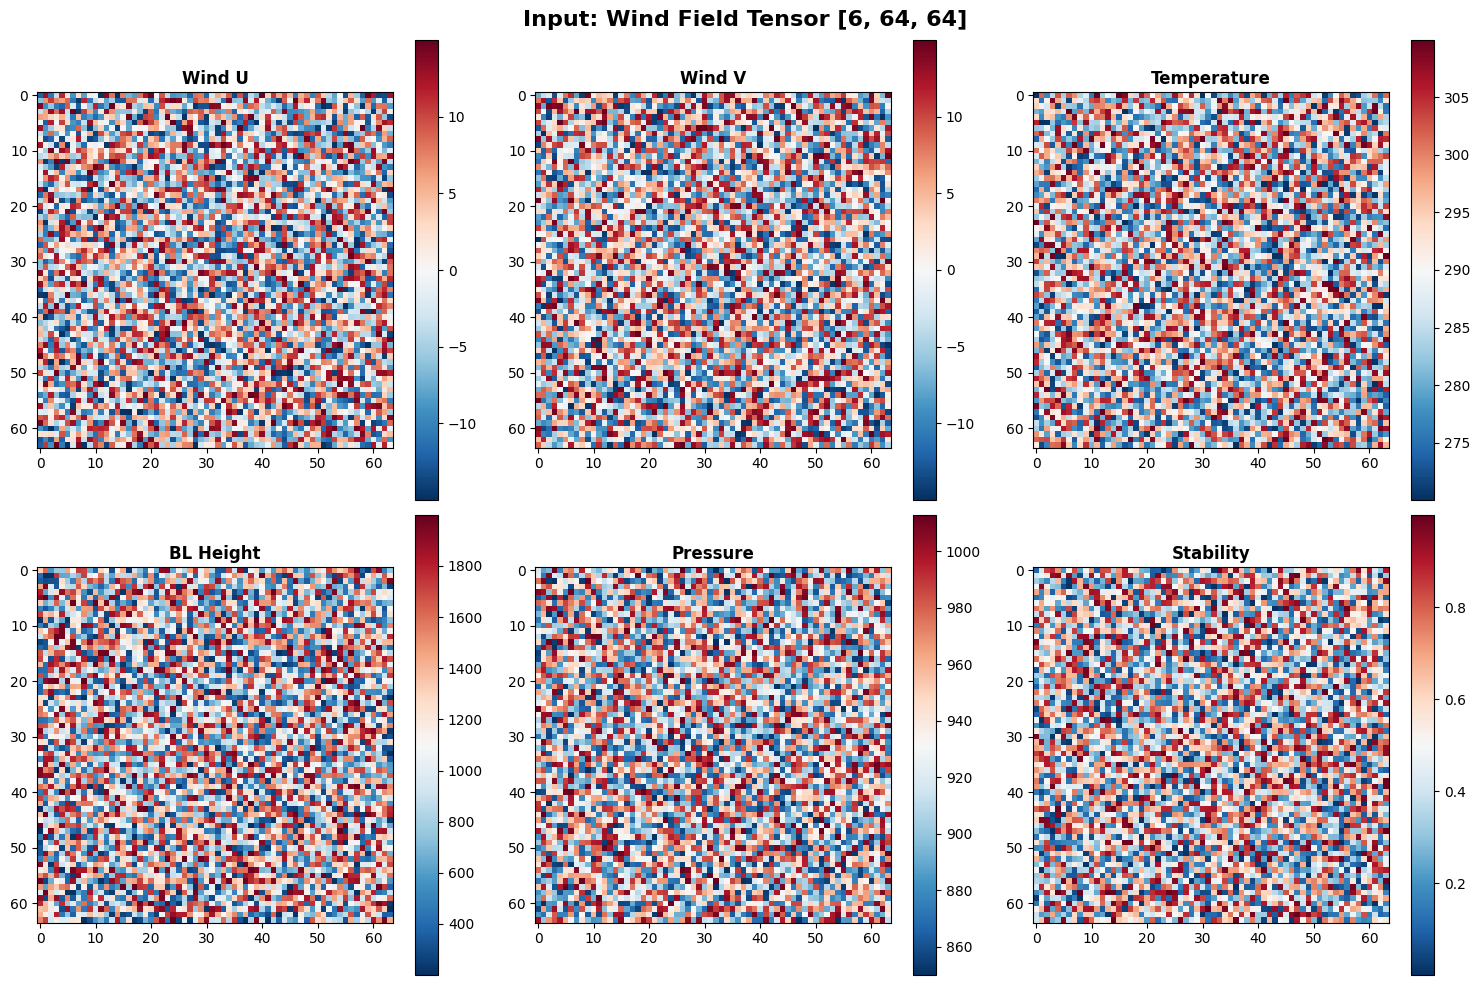

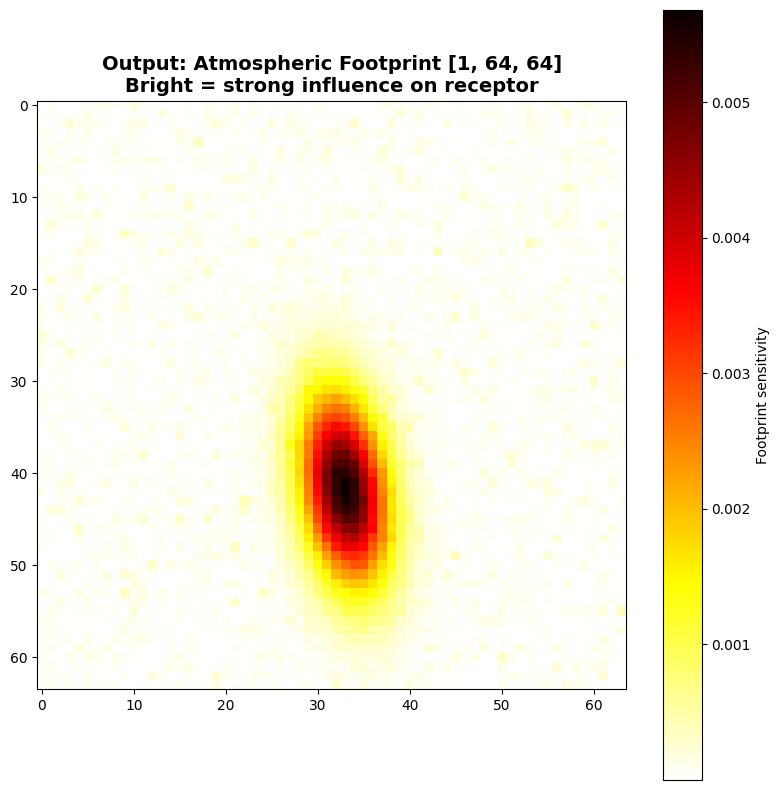

Training pair visualised and saved


In [7]:
# ============================================
# CELL 7 — Visualise a training pair
# ============================================
sample = np.load(files[0])
wind_field = sample['wind_field']
footprint  = sample['footprint']

fig, axes = plt.subplots(2, 3, figsize=(15, 10))

# Plot wind channels
channel_names = ['Wind U', 'Wind V', 'Temperature', 
                 'BL Height', 'Pressure', 'Stability']

for i, (ax, name) in enumerate(zip(axes.flat, channel_names)):
    im = ax.imshow(wind_field[i], cmap='RdBu_r')
    ax.set_title(name, fontweight='bold')
    plt.colorbar(im, ax=ax)

plt.suptitle('Input: Wind Field Tensor [6, 64, 64]', 
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig("../research/preliminary_results/wind_field_tensor.png", dpi=150)
plt.show()

# Plot footprint
fig, ax = plt.subplots(figsize=(8, 8))
im = ax.imshow(footprint[0], cmap='hot_r')
ax.set_title('Output: Atmospheric Footprint [1, 64, 64]\n'
             'Bright = strong influence on receptor', 
             fontsize=14, fontweight='bold')
plt.colorbar(im, ax=ax, label='Footprint sensitivity')
plt.tight_layout()
plt.savefig("../research/preliminary_results/footprint_example.png", dpi=150)
plt.show()

print("Training pair visualised and saved")

In [8]:
# ============================================
# CELL 8 — Create PyTorch dataset class
# Save this — Phase 3 training uses it
# ============================================
dataset_code = '''
import torch
from torch.utils.data import Dataset
import numpy as np
import glob

class FluxaraDataset(Dataset):
    """
    Loads wind_field → footprint training pairs.
    Generated by STILT or synthetic generator.
    """
    def __init__(self, data_dir="../training_data", split="train"):
        self.files = sorted(glob.glob(f"{data_dir}/*.npz"))
        
        # 80/20 train/val split
        n = len(self.files)
        split_idx = int(0.8 * n)
        
        if split == "train":
            self.files = self.files[:split_idx]
        else:
            self.files = self.files[split_idx:]
            
        print(f"{split} dataset: {len(self.files)} samples")
    
    def __len__(self):
        return len(self.files)
    
    def __getitem__(self, idx):
        sample = np.load(self.files[idx])
        wind_field = torch.FloatTensor(sample["wind_field"])
        footprint  = torch.FloatTensor(sample["footprint"])
        return wind_field, footprint

# Test it
dataset = FluxaraDataset()
wind, foot = dataset[0]
print(f"Wind shape: {wind.shape}")
print(f"Foot shape: {foot.shape}")
print("Dataset class working correctly")
'''

# Save to the correct file
with open("../fluxara/training/dataset.py", "w") as f:
    f.write(dataset_code)

exec(dataset_code)
print("Dataset class saved to fluxara/training/dataset.py")

train dataset: 4000 samples
Wind shape: torch.Size([6, 64, 64])
Foot shape: torch.Size([1, 64, 64])
Dataset class working correctly
Dataset class saved to fluxara/training/dataset.py


In [9]:
# ============================================
# CELL 9 — Phase 2 Summary
# ============================================
files = glob.glob("../training_data/*.npz")

print("=" * 50)
print("PHASE 2 COMPLETE")
print("=" * 50)
print()
print(f"Training pairs generated: {len(files):,}")
print()
print("What you now have:")
print(" Synthetic wind→footprint training data")
print(" 5,000 compressed .npz files")
print(" PyTorch Dataset class ready")
print(" Visualisations saved")
print()
print("Files saved:")
print(" training_data/sample_000000.npz to sample_004999.npz")
print(" research/preliminary_results/wind_field_tensor.png")
print(" research/preliminary_results/footprint_example.png")
print(" fluxara/training/dataset.py")
print()
print("Next: Phase 3 — Train the neural network")

PHASE 2 COMPLETE

Training pairs generated: 5,000

What you now have:
 Synthetic wind→footprint training data
 5,000 compressed .npz files
 PyTorch Dataset class ready
 Visualisations saved

Files saved:
 training_data/sample_000000.npz to sample_004999.npz
 research/preliminary_results/wind_field_tensor.png
 research/preliminary_results/footprint_example.png
 fluxara/training/dataset.py

Next: Phase 3 — Train the neural network
